# The two-dimensional classical Ising model

**Goals**

- Express the partition function as a tensor network.
- Approximate its infinite environment with CTMRG.
- Compute magnetization and specific heat, including automatic differentiation.

We use a square lattice with $J=k_B=1$:

$$
\mathcal H=-\sum_{\langle ij\rangle}\sigma_i\sigma_j-H\sum_i\sigma_i,
\qquad \sigma_i\in\{+1,-1\},\qquad \beta=1/T.
$$

For $N$ sites, the partition function is

$$
Z_N(\beta,H)=\sum_{\{\sigma\}}
\prod_{\langle ij\rangle}e^{\beta\sigma_i\sigma_j}
\prod_i e^{\beta H\sigma_i}.
$$

Each edge carries the Boltzmann matrix $h_{ss'}=e^{\beta ss'}$.
Each vertex carries a copy tensor $x_{s_1s_2s_3s_4}=\delta_{s_1s_2s_3s_4}$
and a local field weight $w_s=e^{\beta Hs}$.

```text
    |     |     |
  --x--h--x--h--x--
    |     |     |
    h     h     h
    |     |     |
  --x--h--x--h--x--
    |     |     |
```

For $\beta\geq0$, split each bond using the symmetric **matrix square root**
$q=h^{1/2}$, with $q q=h$. Absorb four half-bonds into each vertex:

$$
A_{uldr}(\beta,H)=\sum_{s=\pm1}q_{us}q_{ls}q_{sd}q_{sr}\,w_s.
$$

Contracting all copies of $A$ gives $Z_N$. The bond dimension is $D=2$;
we order the legs as **up, left, down, right** (`uldr`).


## 1. Construct the site tensor

Build $A(\beta,H)$ with PyTorch and use float64 throughout.
Keep tensor operations in PyTorch so that we can differentiate them later.


In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt


In [2]:
sigma = torch.tensor([1.0, -1.0], dtype=torch.float64)
x = torch.zeros((2, 2, 2, 2), dtype=sigma.dtype)
x[0, 0, 0, 0] = x[1, 1, 1, 1] = 1.0


def sqrt_h(beta):
    """Return the matrix square root of h[s, t] = exp(beta*s*t).
    """
    h = torch.exp(beta * torch.outer(sigma, sigma))
    eigenvalues, eigenvectors = torch.linalg.eigh(h)
    return (eigenvectors * torch.sqrt(eigenvalues)) @ eigenvectors.mT


def Ising_A(beta, H=None):
    """Build the partition-function tensor with legs ordered (up, left, down, right).

    H is the physical magnetic field: the local weight is exp(beta*H*sigma).
    None selects zero field.
    """
    sh = sqrt_h(beta)
    field = torch.as_tensor(
        beta * (0.0 if H is None else H), dtype=sigma.dtype, device=sigma.device
    )
    weights = torch.exp(field * sigma)
    A = torch.einsum("ux,ly,zd,wr,xyzw,x->uldr", sh, sh, sh, sh, x, weights)
    return A


### 1.1. Check lattice symmetries

Verify that $A$ is unchanged by $90^\circ$ rotations and reflections.
The four permutations below act on its `uldr` legs.


In [3]:
beta_check = 1.0

A = Ising_A(beta_check)
assert A.shape == (2, 2, 2, 2)
for permutation in [(1, 2, 3, 0), (3, 0, 1, 2), (2, 1, 0, 3), (0, 3, 2, 1)]:
    torch.testing.assert_close(A, A.permute(permutation))
print("Square-lattice symmetries verified.")


Square-lattice symmetries verified.


## 2. Initialize the CTM boundary

Represent the environment by a corner matrix $C$ and an edge tensor $T$.
Square-lattice symmetry lets us use the same tensors in all four directions.

| Tensor | Shape | Meaning |
|---|---|---|
| $C$ | $(b,b)$ | Corner |
| $T$ | $(b,b,D)$ | Edge |

Here $b\leq\chi$ is the current boundary dimension; $\chi$ is the truncation cap.

```text
    C--1           0---T---1
    |                  |
    0                  2
```

Two starting environments:

- **Open boundary:** absorb half-bonds into boundary copy tensors. Start at
  $b=2$ without zero padding; CTMRG grows the dimension up to $\chi$.
- **Random boundary:** use Gram matrices $C=RR^T$ and
  $T[:,:,s]=R_sR_s^T$ to obtain positive-semidefinite boundaries.

For $q=h^{1/2}$, the zero-field open-boundary construction is

```text
    C-- = x--q           --T-- = q--x--q
    |     |                |        |
          q                         q
```

Random boundaries can select either magnetization branch below $T_c$.
We use them in the observable scans.


In [4]:
def init_obc_CT(beta):
    """Build zero-field open boundaries in their two-dimensional active space.

    Return C.shape == (2, 2) and T.shape == (2, 2, 2). Subsequent CTMRG
    updates grow the active dimension up to chi without padding zero states.
    """
    h = sqrt_h(beta)
    x_C = torch.eye(2, dtype=h.dtype, device=h.device)
    x_T = h.new_zeros((2, 2, 2))
    x_T[0, 0, 0] = x_T[1, 1, 1] = 1

    C = torch.einsum("xd,yr,xy->dr", h, h, x_C)
    T = torch.einsum("lx,yd,zr,xyz->lrd", h, h, h, x_T)
    return C, T


def init_rand_CT(A, chi):
    """Build Gram-matrix boundaries: C and each T[:, :, s] are positive semidefinite."""
    C = torch.rand((chi, chi), dtype=A.dtype, device=A.device)
    T = torch.rand((A.shape[0], chi, chi), dtype=A.dtype, device=A.device)
    C = C @ C.mT
    T = (T @ T.mT).permute(1, 2, 0)
    return C, T


## 3. Enlarge, truncate, and absorb

A **corner transfer matrix renormalization group (CTMRG)** step absorbs one
layer, then compresses the boundary back to at most $\chi$ states.

```text
    C---T---T---T---C
    |   |   |   |   |
    T---A---A---A---T
    |   |   |   |   |
    T---A---A---A---T
    |   |   |   |   |
    T---A---A---A---T
    |   |   |   |   |
    C---T---T---T---C
```

### 3.1. Enlarge the corner

Contract one corner, two edges, and one site tensor.
Pair the open legs to form a $(bD)\times(bD)$ matrix $C'$:

```text
    C---T--        C'==
    |   |     =    ||
    T---A--
    |   |
```


In [5]:
def enlarged_C(A, C, T):
    r"""
    Build enlarged corner tensor

        C----1 1(0)---T--2(1) = C'==2,7
        0             3(2)      ||
        0(1)          3(0)      4,6
        T--5(2) 5(1)--A--7(3)
        4(0)          6(2)
    """
    return torch.einsum(
        C, (0, 1), T, (1, 2, 3), T, (4, 0, 5), A, (3, 5, 6, 7), (4, 6, 2, 7)
    )


### 3.2. Truncate and update the edge

Diagonalize the real symmetric enlarged corner:

$$
C'=U'\operatorname{diag}(S')U'^T.
$$

Keep $r=\min(\chi,bD)$ eigenvectors with the largest eigenvalue magnitudes.
They form an isometry $U\in\mathbb R^{bD\times r}$, with $U^TU=I_r$.

The approximation $U\operatorname{diag}(S)U^T$ minimizes the Frobenius error
among rank-$r$ matrices. In the retained basis, the new corner is diagonal:

$$
C_{\mathrm{new}}=U^TC'U=\operatorname{diag}(S).
$$

For the edge, absorb one $A$ and compress both enlarged boundary legs using $U$.
The bulk leg remains open:

```text
              |
          ----U----
          |       |             |
          T-------A--    =    T_new--
          |       |             |
          ----U----
              |
```

The indexed diagram in `T_absorb` specifies the leg ordering.


In [6]:
def compress(chi, enlarged_C):
    r"""
    Return the retained eigenvalues S and the truncation isometry U.

    The input has shape (b, D, b, D), where b is the current boundary
    dimension. Retain at most min(chi, b*D) eigenvectors,
    ordered by decreasing eigenvalue magnitude. S is a vector of eigenvalues, not a matrix.
    """

    left_chi, left_D, right_chi, right_D = enlarged_C.shape
    matrix = enlarged_C.reshape(left_chi * left_D, right_chi * right_D)
    S, U = torch.linalg.eigh(matrix)
    indices = torch.argsort(S.abs(), descending=True)[:chi]
    S = S[indices]
    U = U[:, indices].reshape(left_chi, left_D, len(indices))
    return S, U


def T_absorb(A, T, U):
    r"""
    Absorb one site into the edge tensor and compress with the corner isometry.

        4(2)
        U
        |---------\
        1(0)       3(1)
        1          3(0)      1
        T--2 2(1)--A--6(3) = T--2
        0          5(2)      0
        0          5(1)
        |----------/
        U^\dag
        7(2)
    """
    return torch.einsum(
        T, (0, 1, 2), U, (1, 3, 4), A, (3, 2, 5, 6), U.conj(), (0, 5, 7), (7, 4, 6)
    )


### 3.3. Compose one CTMRG step

Combine corner enlargement, truncation, and edge absorption.
Store $C_{\mathrm{new}}$ in its diagonal basis.


In [7]:
def ctm_iter(A, C, T, chi):
    r"""
    Perform one CTMRG step, retaining at most chi boundary states.
    """
    S, U = compress(chi, enlarged_C(A, C, T))
    C_n = torch.diag(S)
    T_n = T_absorb(A, T, U)
    return C_n, T_n


## 4. Iterate to a fixed point

After each update:

1. Normalize $C$ and $T$ by their largest absolute entries.
2. Symmetrize the first two legs of $T$ to suppress roundoff errors.
3. Compare consecutive normalized corner spectra, sorted by eigenvalue magnitude.

Stop when the summed absolute spectrum difference is below the tolerance.
If the iteration cap is reached, the environment may still be unconverged.

Scalar normalizations cancel in the observable ratios below.
Finite-$\chi$ errors remain: check larger $\chi$ near the transition.


In [8]:
def ctmrg(
    A,
    C,
    T,
    chi,
    ctm_max_iter=100,
    ctm_conv_tol=1.0e-8,
    callback=None,
    raise_on_nonconvergence=False,
):
    """Iterate CTMRG, retaining at most chi states.

    callback(i, residual, finished, A, C, T) monitors each update.
    finished marks convergence or the final allowed iteration.
    Smaller initial boundaries grow up to chi. The stopping test uses no_grad.
    """

    with torch.no_grad():
        spectrum = torch.linalg.eigvalsh(C)
        indices = torch.argsort(spectrum.abs(), descending=True)
        previous_spectrum = spectrum[indices] / spectrum.abs().max()

    for i in range(ctm_max_iter):
        C, T = ctm_iter(A, C, T, chi)
        C = C / C.abs().max()
        T = (T + T.permute(1, 0, 2)) / 2
        T = T / T.abs().max()

        # Compute the corner spectrum difference
        with torch.no_grad():
            spectrum = C.diagonal()
            indices = torch.argsort(spectrum.abs(), descending=True)
            spectrum = spectrum[indices]
            # Boundary dimensions may grow during the first few updates.
            size = max(spectrum.numel(), previous_spectrum.numel())
            current_padded = torch.nn.functional.pad(
                spectrum, (0, size - spectrum.numel())
            )
            previous_padded = torch.nn.functional.pad(
                previous_spectrum, (0, size - previous_spectrum.numel())
            )
            residual = (current_padded - previous_padded).abs().sum()
            converged = bool(residual < ctm_conv_tol)
            previous_spectrum = spectrum

        if callback is not None:
            finished = converged or i == ctm_max_iter - 1
            callback(i, residual, finished, A, C, T)
        if converged:
            break

    if raise_on_nonconvergence and not converged:
        raise RuntimeError(
            f"CTMRG did not converge in {ctm_max_iter} iterations: "
            f"residual={residual.item():.3e}, tolerance={ctm_conv_tol:.3e}."
        )
    return C, T


## 5. Measure the magnetization

Insert a factor of $s$ into the site tensor to obtain the impurity tensor $B$:

$$
B_{uldr}=\sum_{s=\pm1}q_{us}q_{ls}q_{sd}q_{sr}\,w_s\,s.
$$

Contract four corners and four edges into the one-site environment
$\rho_{uldr}$. The magnetization is the normalized contraction

$$
m=\langle\sigma_i\rangle
=\frac{\sum_{uldr}\rho_{uldr}B_{uldr}}
       {\sum_{uldr}\rho_{uldr}A_{uldr}}.
$$

```text
       C---T---C         C---T---C
       |   |   |         |   |   |
  m =  T---B---T    /    T---A---T
       |   |   |         |   |   |
       C---T---C         C---T---C
```

Use the same $\beta$ and $H$ for $A$ and $B$.


In [10]:
def f_B(beta, H=None):
    r"""
    Build the magnetization impurity tensor B at the same beta and H as A.
    """
    h = sqrt_h(beta)
    field = torch.as_tensor(
        beta * (0.0 if H is None else H), dtype=sigma.dtype, device=sigma.device
    )
    weights = torch.exp(field * sigma) * sigma
    B = torch.einsum("ux,ly,zd,wr,xyzw,x->uldr", h, h, h, h, x, weights)
    return B


def aux_rho_1x1(C, T):
    r"""
    Contract four corners and four edges into rho[up, left, down, right].

        i) C--1 1(0)--T--2(1) = C--T--1
           |          |         |  |
           0          3(2)      0  2

        ii) C--T--1 1(0)--C  =  C--T-----C
            |  |          |     |  |     |
            0  2          |     0  2  3--T
                    4(2)--T              |
                          |              1
                          3(1)

        iii) C------T-------C                C------T------C
             0      |       |                |      |      |
             0(1)   2       |                |      0      |
             T---4(3)    3--T        =       T---1      3--T
             |      5(2)    1                |      2      |
             |      |       1(0)             |      |      |
             C------T-------C                C------T------C
    """
    rho = torch.einsum(C, (0, 1), T, (1, 2, 3), (0, 2, 3))
    rho = torch.einsum(rho, (0, 1, 2), rho, (1, 3, 4), (0, 3, 2, 4))
    rho = torch.einsum(rho, (0, 1, 2, 3), rho, (1, 0, 5, 4), (2, 4, 5, 3))
    return rho


def eval_1x1(B, A, rho):
    r"""
    Return the normalized expectation value of B in the environment rho.
    """
    return torch.einsum("uldr,uldr", rho, B) / torch.einsum("uldr,uldr", rho, A)


## 6. Compare with the exact magnetization

At zero field, the critical inverse temperature is

$$
\beta_c=\frac12\log(1+\sqrt2).
$$

The positive spontaneous-magnetization branch is

$$
m_{\mathrm{exact}}(\beta)=
\begin{cases}
0,&\beta\leq\beta_c,\\
\left[1-\sinh^{-4}(2\beta)\right]^{1/8},&\beta>\beta_c.
\end{cases}
$$

- A finite spin-symmetric system has $m=0$ at $H=0$.
- Spontaneous magnetization takes the thermodynamic limit before $H\to0^+$.
- Random boundaries select either sign, so compare $|m|$ with the positive branch.

Use a fixed seed for reproducibility. Check the final convergence residual at
each temperature.


In [11]:
def report_ctm(i, residual, finished, A, C, T):
    """Print the final iteration count and corner-spectrum residual."""
    if finished:
        print(f"iterations={i + 1}, residual={residual.item():.2e}")


torch.manual_seed(7)
chi = 12
betas = np.linspace(0.1, 0.6, 20)
magnetizations = []

with torch.no_grad():
    for beta in betas:
        print(f"beta={beta:.4f}", end=", ")
        A = Ising_A(beta)
        C, T = ctmrg(
            A,
            *init_rand_CT(A, chi),
            chi,
            ctm_max_iter=3000,
            ctm_conv_tol=1.0e-8,
            callback=report_ctm,
        )
        m = eval_1x1(f_B(beta), A, aux_rho_1x1(C, T))
        magnetizations.append(m.item())


beta=0.1000, iterations=6, residual=4.11e-09
beta=0.1263, iterations=7, residual=4.20e-09
beta=0.1526, iterations=8, residual=5.58e-09
beta=0.1789, iterations=9, residual=5.70e-09
beta=0.2053, iterations=11, residual=1.77e-09
beta=0.2316, iterations=12, residual=4.90e-09
beta=0.2579, iterations=14, residual=4.49e-09
beta=0.2842, iterations=16, residual=9.51e-09
beta=0.3105, iterations=20, residual=9.53e-09
beta=0.3368, iterations=32, residual=9.30e-09
beta=0.3632, iterations=44, residual=9.73e-09
beta=0.3895, iterations=61, residual=9.83e-09
beta=0.4158, iterations=99, residual=9.34e-09
beta=0.4421, iterations=1066, residual=9.88e-09
beta=0.4684, iterations=114, residual=9.50e-09
beta=0.4947, iterations=173, residual=7.12e-09
beta=0.5211, iterations=798, residual=9.66e-09
beta=0.5474, iterations=143, residual=4.03e-09
beta=0.5737, iterations=85, residual=6.16e-09
beta=0.6000, iterations=159, residual=1.29e-09


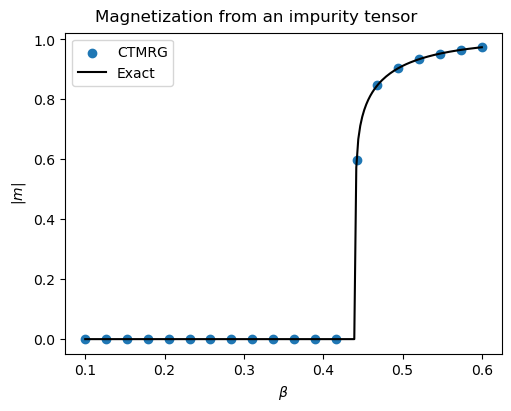

In [12]:
def exact_magnetization(beta):
    """Return the positive spontaneous magnetization, including the disordered phase."""
    beta = np.asarray(beta, dtype=float)
    beta_c = np.log1p(np.sqrt(2)) / 2
    ordered = beta > beta_c
    result = np.zeros_like(beta)
    result[ordered] = (1 - np.sinh(2 * beta[ordered]) ** (-4)) ** (1 / 8)
    return result


def plot_magnetization(betas, values, title):
    """Compare |m| with the exact zero-field magnetization."""
    values = np.abs(np.asarray(values, dtype=float))
    beta_grid = np.linspace(betas.min(), betas.max(), 200)
    fig, ax = plt.subplots(1, 1, figsize=(5, 4), constrained_layout=True)
    ax.scatter(betas, values, label="CTMRG")
    ax.plot(beta_grid, exact_magnetization(beta_grid), color="black", label="Exact")
    ax.set(xlabel=r"$\beta$", ylabel=r"$|m|$")
    ax.legend()
    fig.suptitle(title)
    return fig, ax


fig_impurity, ax_impurity = plot_magnetization(
    betas, magnetizations, "Magnetization from an impurity tensor"
)
plt.show()


## 7. Compute the partition function per site

The partition function per site $z$ and the free energy per site $f$ are

$$
z=\lim_{N\to\infty}Z_N^{1/N},\qquad
\log z=\lim_{N\to\infty}\frac{\log Z_N}{N},\qquad
f=-\frac{\log z}{\beta},
$$

where $N$ is the total number of sites.

### 7.1. Contract four patches

A single patch contraction depends on the normalization of $C$ and $T$,
which are rescaled at every CTMRG step.
To cancel these scale factors, form four scalars from the **same converged environment**:

```text
       C---T---C              C-------C
       |   |   |              |       |
  Z1 = T---A---T         Z2 = |       |
       |   |   |              |       |
       C---T---C              C-------C

       C---T---C              C-------C
       |   |   |              |       |
  Z3 = |   |   |         Z4 = T-------T
       |   |   |              |       |
       C---T---C              C-------C
```

The partition function per site is estimated by

$$
\boxed{z=\frac{Z_1Z_2}{Z_3Z_4}}.
$$

To motivate the ratio, imagine that $C$ represents an $L\times L$ quadrant
and $T$ a strip of length $L$. The four patches have areas
$(2L+1)^2$, $(2L)^2$, $2L(2L+1)$, and $2L(2L+1)$, respectively. 
As a result
$$
\frac{Z_1 Z_2}{Z_3 Z_4} = z^{(2L+1)^2+(2L)^2-2(2L)(2L+1)} = z.
$$

Importantly, the formula is insensitive to the normalization of $C$ and $T$.
Specifically, under $C\mapsto cC$ and $T\mapsto tT$,

$$
Z_1\mapsto c^4t^4Z_1,\quad Z_2\mapsto c^4Z_2,\quad
Z_3\mapsto c^4t^2Z_3,\quad Z_4\mapsto c^4t^2Z_4.
$$
These scale factors cancel exactly in the ratio, so no CTMRG normalization history is needed.
Rotational symmetry gives $Z_3=Z_4$, so compute this contraction once.


In [13]:
def partition_contractions(A, C, T):
    """Return Z1, Z2, Z3, Z4 from the four CTM diagrams above.

    Assumes real, reflection-symmetric tensors shared by all directions.
    Consequently the two rectangular contractions satisfy Z3 == Z4.
    """
    rho = aux_rho_1x1(C, T)
    Z1 = torch.einsum("uldr,uldr->", rho, A)
    Z2 = torch.trace(torch.linalg.matrix_power(C, 4))

    # One half of a rectangular patch: two corners and one edge.
    half_rectangle = torch.einsum("xy,yz,zwp->xpw", C, C, T)
    Z3 = torch.einsum("xpw,wpx->", half_rectangle, half_rectangle)
    Z4 = Z3  # Rotational symmetry, not a separate approximation.
    return Z1, Z2, Z3, Z4


def eval_log_z(A, C, T):
    """Estimate log(z) = -beta*f from a converged isotropic CTM environment.

    The four scalar contractions are positive for the physical environment.
    Scalar rescalings of C and T cancel; a rescaling of A does not.
    """
    Z1, Z2, Z3, Z4 = partition_contractions(A, C, T)
    return Z1.log() + Z2.log() - Z3.log() - Z4.log()


def eval_z(A, C, T):
    """Estimate z = lim Z_N**(1/N), the partition function per site."""
    return eval_log_z(A, C, T).exp()


## 8. Observables from automatic differentiation

Magnetization, energy per site, and specific heat follow from derivatives of $\log z$.
At $H=0$,

$$
m=\frac1\beta\frac{\partial\log z}{\partial H},\qquad
u=-\frac{\partial\log z}{\partial\beta},\qquad
c_V=\frac{\partial u}{\partial T}
=\beta^2\frac{\partial^2\log z}{\partial\beta^2}.
$$

PyTorch records the operations that connect $\beta$ and $H$ to $\log z$,
including the CTMRG iterations.
The function [`torch.autograd.grad`](https://docs.pytorch.org/docs/stable/generated/torch.autograd.grad.html)
applies the chain rule through this computation graph to evaluate the derivatives automatically. In the following,
use this function to compute the observables mentioned. Two options are needed here:
- `retain_graph=True`: preserve the graph after the field derivative so it can be reused for the temperature derivatives.
- `create_graph=True`: record the first temperature derivative so it can be differentiated again.

Random boundaries can select a magnetization branch below $T_c$.
Second derivatives require careful convergence; check the CTMRG tolerance and $\chi$.


In [14]:
def obs_from_AD(betas, chi, ctm_max_iter=10000, ctm_conv_tol=1e-9):
    """Return zero-field magnetization and specific heat from derivatives of log(z)."""
    m_ad = []
    cv_ad = []

    for beta_value in betas:
        H = torch.zeros((), dtype=sigma.dtype, requires_grad=True)
        beta = torch.tensor(beta_value, dtype=sigma.dtype, requires_grad=True)
        A = Ising_A(beta, H)
        C, T = ctmrg(
            A,
            *init_rand_CT(A, chi),
            chi,
            ctm_max_iter=ctm_max_iter,
            ctm_conv_tol=ctm_conv_tol,
            raise_on_nonconvergence=True,
        )
        log_z = eval_log_z(A, C, T)
        # Reuse this graph for the temperature derivatives.
        (dlog_z_dH,) = torch.autograd.grad(log_z, H, retain_graph=True)
        m_ad.append((dlog_z_dH / beta).item())

        # Keep the first derivative differentiable to obtain c_V.
        (dlog_z_dbeta,) = torch.autograd.grad(log_z, beta, create_graph=True)
        (d2log_z_dbeta2,) = torch.autograd.grad(dlog_z_dbeta, beta)
        cv_ad.append((beta**2 * d2log_z_dbeta2).item())

    return m_ad, cv_ad


### 8.1. Exact specific heat (reference)

Use the zero-field square-lattice formula below. Its logarithmic divergence
marks $\beta_c$; finite $\chi$ limits accuracy near the peak.

Reference: [Caux, Eq. (126)](https://jscaux.org/static/jsc/courses/2019_FPITFT/FROM_PI_TO_FT_2019_notes.pdf).


In [15]:
def exact_specific_heat(beta):
    """Exact zero-field specific heat per site for beta > 0 and J = k_B = 1."""
    from scipy.special import ellipk, ellipe

    beta = np.asarray(beta, dtype=float)
    t = np.tanh(2 * beta)
    k = 2 * t / np.cosh(2 * beta)
    K, E = ellipk(k**2), ellipe(k**2)  # SciPy uses the parameter k**2.
    return (
        4
        / np.pi
        * (beta / t) ** 2
        * (K - E - (1 - t**2) * (np.pi / 2 + (2 * t**2 - 1) * K))
    )


def plot_specific_heat(betas, values):
    """Compare CTMRG specific heat with the exact zero-field curve."""
    betas = np.asarray(betas)
    grid = np.linspace(betas.min(), betas.max(), 400)
    fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
    ax.plot(grid, exact_specific_heat(grid), color="black", label="Exact")
    ax.scatter(betas, values, label="CTMRG")
    ax.axvline(
        np.log1p(np.sqrt(2)) / 2, color="gray", linestyle="--", label=r"$\beta_c$"
    )
    ax.set(xlabel=r"$\beta$", ylabel=r"$c_V$", title="Specific heat per site")
    ax.legend()
    return fig, ax


### 8.2. Compare both observables

Sample more densely near $\beta_c$ and compare the AD results with the exact curves.


In [ ]:
torch.manual_seed(7)
chi = 12
betas = np.concatenate(
    [np.linspace(0.3, 0.41, 5), np.linspace(0.43, 0.45, 10), np.linspace(0.48, 0.6, 5)]
)
m_ad, cv_ad = obs_from_AD(betas, chi)


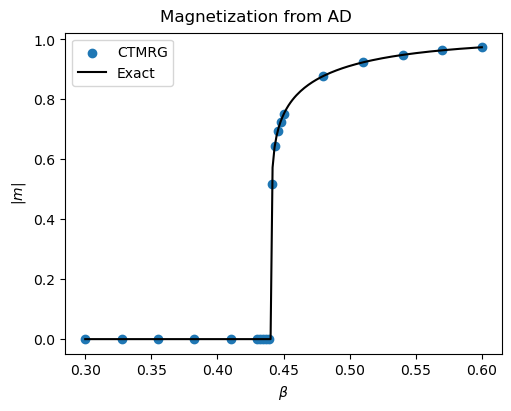

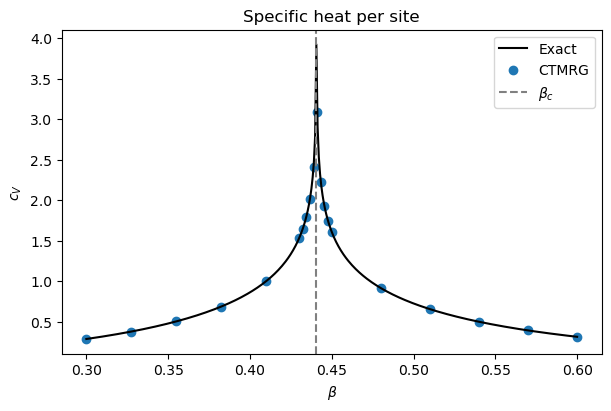

In [19]:
fig_m, ax_m = plot_magnetization(betas, m_ad, "Magnetization from AD")
fig_heat, ax_heat = plot_specific_heat(betas, cv_ad)

plt.show()


### 9.1. Critical slowing down

Long correlations require more CTMRG updates to resolve. Compare temperatures
using fixed $\chi$, tolerance, and random starting tensors.

Build an effective one-column transfer matrix from two edges and one site:

```text
    a---T---b
        | u
    l---A---r
        | v
    c---T---d
```

Group $(a,c,l)$ and $(b,d,r)$ into matrix indices. From its two largest
eigenvalue magnitudes, estimate the correlation length in lattice spacings:

$$
\mathcal E_{(acl),(bdr)}=\sum_{uv}T_{abu}A_{ulvr}T_{cdv},\qquad
\xi=-\frac{1}{\log|\lambda_1/\lambda_0|}.
$$

Runtime below measures **CTMRG only**, excluding transfer-matrix diagonalization.
Finite $\chi$ rounds the divergence and can shift the peak away from $\beta_c$.


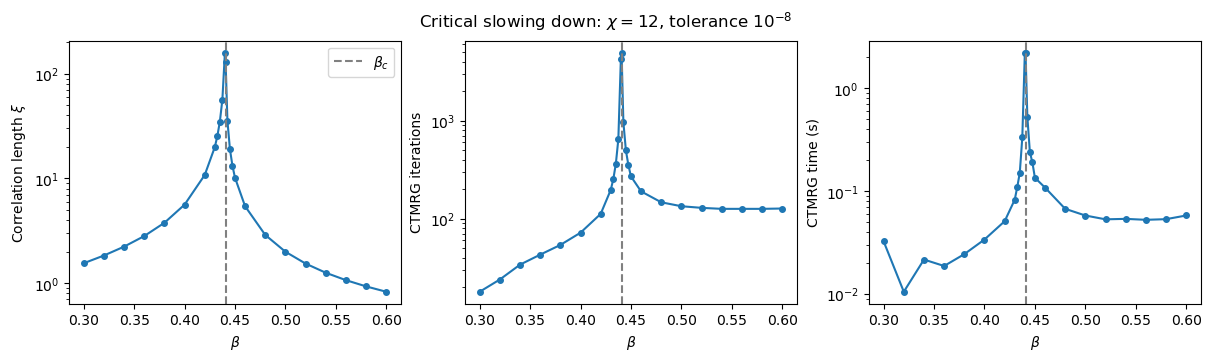

At beta_c: xi=128.5, iterations=4941, time=2.22 s


In [20]:
from time import perf_counter


def correlation_length(A, T):
    """Estimate the dominant transfer correlation length in lattice spacings."""
    b, _, D = T.shape
    transfer = torch.einsum("abu,ulvr,cdv->aclbdr", T, A, T)
    transfer = transfer.reshape(b * b * D, b * b * D)
    eigenvalues = torch.linalg.eigvalsh(transfer).abs().sort(descending=True).values
    return (-1 / torch.log(eigenvalues[1] / eigenvalues[0])).item()


chi_scan = 12
ctm_tol_scan = 1.0e-8
beta_c = np.log1p(np.sqrt(2)) / 2
betas_scan = np.unique(
    np.r_[np.linspace(0.3, 0.6, 16), np.linspace(0.43, 0.45, 9), beta_c]
)
ctm_iterations = []
ctm_seconds = []
correlation_lengths = []


def record_iterations(i, residual, finished, A, C, T):
    if finished:
        ctm_iterations.append(i + 1)


with torch.no_grad():
    for beta_scan in betas_scan:
        # Identical random starting tensors at each beta; no warm starts.
        torch.manual_seed(7)
        A_scan = Ising_A(beta_scan)
        C0, T0 = init_rand_CT(A_scan, chi_scan)
        start = perf_counter()
        C_scan, T_scan = ctmrg(
            A_scan,
            C0,
            T0,
            chi_scan,
            ctm_max_iter=10000,
            ctm_conv_tol=ctm_tol_scan,
            callback=record_iterations,
            raise_on_nonconvergence=True,
        )
        ctm_seconds.append(perf_counter() - start)
        correlation_lengths.append(correlation_length(A_scan, T_scan))

fig_convergence, axes_convergence = plt.subplots(
    1, 3, figsize=(12, 3.5), sharex=True, constrained_layout=True
)
for ax, values, label in zip(
    axes_convergence,
    [correlation_lengths, ctm_iterations, ctm_seconds],
    [r"Correlation length $\xi$", "CTMRG iterations", "CTMRG time (s)"],
):
    ax.plot(betas_scan, values, "o-", markersize=4)
    ax.axvline(beta_c, color="gray", linestyle="--", label=r"$\beta_c$")
    ax.set(xlabel=r"$\beta$", ylabel=label, yscale="log")
axes_convergence[0].legend()
fig_convergence.suptitle(
    rf"Critical slowing down: $\chi={chi_scan}$, tolerance $10^{{-8}}$"
)
plt.show()

j = np.argmin(np.abs(betas_scan - beta_c))
print(
    f"At beta_c: xi={correlation_lengths[j]:.1f}, "
    f"iterations={ctm_iterations[j]}, time={ctm_seconds[j]:.2f} s"
)
